In [110]:
# Librerias base para manipulacion de datos, visualizacion y operaciones numericas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [111]:
# Carga del dataset de entrenamiento desde GitHub
# Contiene 48.000 registros de cargas con rutas, equipos, pesos, fechas y tarifas publicadas
train = pd.read_csv(
    "https://raw.githubusercontent.com/jhon1142/Machine-Learning-Engineer-SPOTTER/refs/heads/main/train-test.csv"
)
train

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


In [112]:
# Carga del dataset de validacion (Nov - Dic 2025)
# No contiene la columna posted_rate; el objetivo es predecirla con el modelo entrenado
validation = pd.read_csv(
    "https://raw.githubusercontent.com/jhon1142/Machine-Learning-Engineer-SPOTTER/refs/heads/main/validation.csv"
)
validation

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,TE-011996,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,2.15984
11996,TE-011997,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,2.46279
11997,TE-011998,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,2.09568
11998,TE-011999,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,1.95125


# Exploracion de Datos (EDA)

El objetivo de esta seccion es entender la estructura del dataset, detectar anomalias, valores faltantes y patrones relevantes que guien las decisiones de preprocesamiento y modelado.

In [113]:
# Vista general del dataset: dimensiones, tipos de datos y estadisticas descriptivas
# Esto permite identificar rapidamente el volumen de datos, variables disponibles
# y si existen valores faltantes o discrepancias entre conteos
print("Dimensiones del dataset:", train.shape)
train.info()
display(train.describe(include="all").T)
display(train.dtypes.to_frame(name="Tipo de dato"))
display(train.nunique().to_frame(name="Valores unicos"))

Dimensiones del dataset: (48000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
load_id,48000,48000,TR-047961,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup,48000,64,Oklahoma City,1242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery,48000,64,Lexington,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_lat,48000.0,NaN,NaN,NaN,35.647545,4.315285,28.35765,31.98691,35.29479,39.41104,44.30296
pickup_lon,48000.0,NaN,NaN,NaN,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.28506,-69.5
delivery_lat,48000.0,NaN,NaN,NaN,35.641175,4.317199,28.35765,31.98691,35.29479,39.41104,44.30296
delivery_lon,48000.0,NaN,NaN,NaN,-90.85731,13.476589,-121.69849,-98.40059,-87.52871,-83.28506,-69.5
distance,48000.0,NaN,NaN,NaN,1135.856654,728.564416,70.0,550.4,953.3,1645.525,3439.8
equipment,48000,3,Dry Van,27202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,47700.0,NaN,NaN,NaN,31028.844004,9391.44062,-47500.0,25800.0,31436.5,37018.0,47500.0


,Tipo de dato
load_id,object
pickup,object
delivery,object
pickup_lat,float64
pickup_lon,float64
delivery_lat,float64
delivery_lon,float64
distance,float64
equipment,object
weight,float64


,Valores unicos
load_id,48000
pickup,64
delivery,64
pickup_lat,64
pickup_lon,63
delivery_lat,64
delivery_lon,63
distance,21204
equipment,3
weight,23678


**Observacion:** Las columnas `weight` y `market_index` presentan valores nulos. Se analizara cada una para decidir la estrategia de imputacion mas adecuada.

## Limpieza de Datos

In [114]:
# Calculo del porcentaje de valores nulos por columna
# Se identifican tambien registros duplicados y valores unicos en variables categoricas
missing = pd.DataFrame({
    "Missing": train.isnull().sum(),
    "Percentage": train.isnull().mean() * 100
})
missing = missing.sort_values("Percentage", ascending=False)
display(missing)

print("Registros duplicados:", train.duplicated().sum())
print("Load IDs duplicados:", train["load_id"].duplicated().sum())

categorical_cols = ["pickup", "delivery", "equipment"]
for col in categorical_cols:
    print(f"\n{col}:")
    print(train[col].value_counts(dropna=False).head(15))

,Missing,Percentage
market_index,374,0.779167
weight,300,0.625000
delivery,0,0.000000
pickup_lat,0,0.000000
load_id,0,0.000000
pickup,0,0.000000
delivery_lat,0,0.000000
pickup_lon,0,0.000000
distance,0,0.000000
delivery_lon,0,0.000000


Registros duplicados: 0
Load IDs duplicados: 0

pickup:
pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
Richmond         1140
Nashville        1124
Phoenix          1121
Baton Rouge      1115
Mobile           1094
Cincinnati       1080
Shreveport       1062
Kansas City      1053
Columbia         1049
Atlanta          1029
Name: count, dtype: int64

delivery:
delivery
Lexington        1197
Fort Wayne       1176
Baton Rouge      1167
Bakersfield      1156
Hartford         1143
Oklahoma City    1140
Richmond         1109
Atlanta          1096
Phoenix          1090
Mobile           1089
Cincinnati       1084
Columbia         1071
Nashville        1064
Tucson            997
Shreveport        983
Name: count, dtype: int64

equipment:
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64


### Analisis de valores negativos en `weight`

Se detectaron pesos con signo negativo. Esto es anomalo fisicamente, ya que el peso de una carga no puede ser negativo. Se investiga si es un error sistematico de captura (signo invertido) o datos corruptos.

In [115]:
# Separar registros con pesos negativos y positivos para cuantificar la anomalia
negative_weights = train[train["weight"] < 0]
positive_weights = train[train["weight"] > 0]

print("Total de registros:", len(train))
print("Pesos negativos:", len(negative_weights))
print("Pesos positivos:", len(positive_weights))
print("Porcentaje negativo:",
      round(len(negative_weights) / len(train) * 100, 2), "%")

display(negative_weights["weight"].describe())

display(pd.DataFrame({
    "Negative": negative_weights["weight"].describe(),
    "Positive": positive_weights["weight"].describe()
}))

Total de registros: 48000
Pesos negativos: 292
Pesos positivos: 47408
Porcentaje negativo: 0.61 %


count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64

,Negative,Positive
count,292.000000,47408.000000
mean,-31724.195205,31415.358674
std,8262.536326,7994.902979
min,-47500.000000,5000.000000
25%,-37284.250000,25922.000000
50%,-31821.500000,31493.500000
75%,-25928.500000,37063.000000
max,-5000.000000,47500.000000


Se analiza la distribucion de pesos negativos por tipo de equipo para verificar si el error esta concentrado en algun segmento especifico o es transversal a todos.

In [116]:
# Distribucion de pesos negativos por tipo de equipo
# Si el patron es uniforme entre equipos, confirma que es un error sistematico de signo
negative_analysis = (
    train.assign(is_negative=train["weight"] < 0)
    .groupby("equipment")
    .agg(
        total_loads=("load_id", "count"),
        negative_weights=("is_negative", "sum"),
        avg_weight=("weight", "mean")
    )
)
negative_analysis["negative_percentage"] = (
    negative_analysis["negative_weights"] /
    negative_analysis["total_loads"] * 100
)
display(negative_analysis.round(2))

,total_loads,negative_weights,avg_weight,negative_percentage
equipment,,,,
Dry Van,27202,155,31027.29,0.57
Flatbed,8753,70,30963.63,0.80
Reefer,12045,67,31079.71,0.56


Se revisan tambien valores nulos y ceros en `weight` para completar el diagnostico.

In [117]:
# Conteo de valores nulos y ceros en la columna weight
print("Pesos iguales a cero:", (train["weight"] == 0).sum())
print("Pesos nulos (NaN):", train["weight"].isna().sum())
print("Total sin clasificar (nulos o cero):",
      (train["weight"].isna() | (train["weight"] == 0)).sum())

Pesos iguales a cero: 0
Pesos nulos (NaN): 300
Total sin clasificar (nulos o cero): 300


Se identificaron **300 valores nulos** en `weight`. Se imputaran con la mediana del conjunto de entrenamiento para evitar sesgos por outliers.

### Validacion de la hipotesis de error de signo

Si los valores absolutos de los pesos negativos siguen la misma distribucion que los pesos positivos, entonces se trata de un error sistematico de signo y la correccion correcta es aplicar `abs()`.

In [118]:
# Comparacion estadistica entre pesos positivos y valores absolutos de pesos negativos
# Si las distribuciones son similares, confirma el error de signo
positive = train.loc[train["weight"] > 0, "weight"]
negative_abs = train.loc[train["weight"] < 0, "weight"].abs()

display(pd.DataFrame({
    "Positive weights": positive.describe(),
    "Absolute negative weights": negative_abs.describe()
}))

,Positive weights,Absolute negative weights
count,47408.000000,292.000000
mean,31415.358674,31724.195205
std,7994.902979,8262.536326
min,5000.000000,5000.000000
25%,25922.000000,25928.500000
50%,31493.500000,31821.500000
75%,37063.000000,37284.250000
max,47500.000000,47500.000000


Visualizacion de las distribuciones para comparacion visual directa:

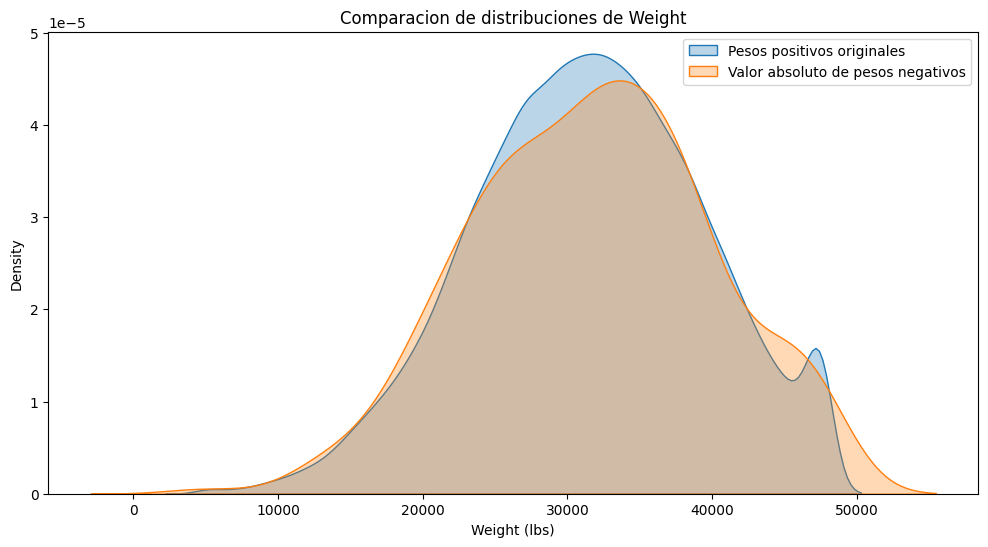

In [119]:
# Grafico KDE: si las curvas se superponen, confirma que los negativos son errores de signo
plt.figure(figsize=(12, 6))
sns.kdeplot(positive, label="Pesos positivos originales", fill=True, alpha=0.3)
sns.kdeplot(negative_abs, label="Valor absoluto de pesos negativos", fill=True, alpha=0.3)
plt.title("Comparacion de distribuciones de Weight")
plt.xlabel("Weight (lbs)")
plt.legend()
plt.show()

**Conclusion:** Las curvas se superponen casi perfectamente, lo que confirma que los valores negativos son errores de captura (signo invertido). La correccion adecuada es aplicar `abs()` a toda la columna `weight` y registrar cuales fueron corregidos mediante un flag binario `weight_sign_corrected`.

In [120]:
# Diagnostico de valores faltantes y ceros en market_index
print("Valores nulos en market_index:", train["market_index"].isna().sum())
print("Total sin clasificar (nulos o cero):",
      (train["market_index"].isna() | (train["market_index"] == 0)).sum())

Valores nulos en market_index: 374
Total sin clasificar (nulos o cero): 374


`market_index` presenta **374 valores nulos** (~0.8% del total). Se imputaran con la mediana del conjunto de entrenamiento. Ademas, se creara un flag `market_index_missing` para que el modelo pueda aprender si la ausencia de este valor tiene valor predictivo.

### Correccion de pesos negativos

In [121]:
# Paso 1: crear flag binario antes de corregir (1 = el signo fue corregido)
# Esto permite que el modelo aprenda si la correccion de signo tiene algun efecto en la tarifa
train["weight_sign_corrected"] = (train["weight"] < 0).astype(int)

# Paso 2: aplicar valor absoluto para corregir el signo
train["weight"] = train["weight"].abs()

print("Registros con signo corregido:", train["weight_sign_corrected"].sum())
print("Pesos negativos restantes:", (train["weight"] < 0).sum())

Registros con signo corregido: 292
Pesos negativos restantes: 0


### Analisis de la distribucion de `market_index` antes de imputar

count    47626.000000
mean         1.083387
std          0.168091
min          0.676390
25%          0.949670
50%          1.055800
75%          1.219590
max          1.467780
Name: market_index, dtype: float64

Skewness: 0.2143
Kurtosis: -1.011


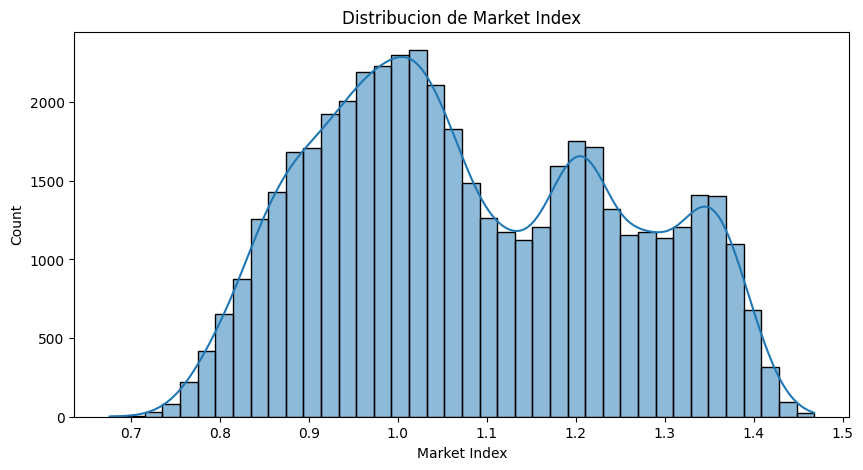

In [122]:
# Estadisticas y visualizacion de market_index para elegir la estrategia de imputacion
# Se revisa asimetria (skewness) y curtosis para decidir entre media y mediana
display(train["market_index"].describe())
print("Skewness:", round(train["market_index"].skew(), 4))
print("Kurtosis:", round(train["market_index"].kurt(), 4))

plt.figure(figsize=(10, 5))
sns.histplot(data=train, x="market_index", kde=True, bins=40)
plt.title("Distribucion de Market Index")
plt.xlabel("Market Index")
plt.show()

**Interpretacion del histograma de `market_index`:**

- La distribucion es **multimodal**, con picos visibles alrededor de 1.0, 1.2 y 1.35.
- No sigue una distribucion normal (kurtosis negativa ~ -1.0, distribucion platicurtica).
- Dado que la distribucion tiene varios modos y no es simetrica, se elige la **mediana** como estadistico de imputacion para ser robusta frente a los extremos.

## Analisis Univariado

Se visualizan las distribuciones de todas las variables numericas para identificar asimetrias, rangos anormales y posibles outliers.

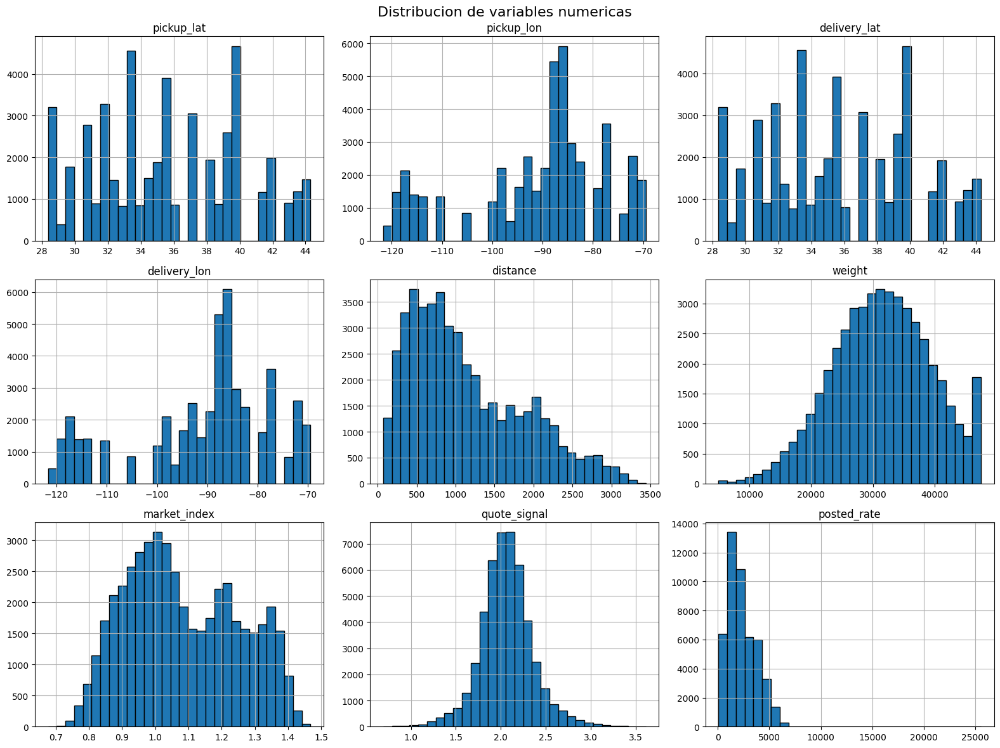

In [123]:
# Histogramas de todas las variables numericas
# posted_rate muestra fuerte asimetria positiva (cola a la derecha)
# distance tambien es asimetrica, con muchas cargas de distancia media
numeric_cols = [
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
    "distance", "weight", "market_index", "quote_signal", "posted_rate"
]
train[numeric_cols].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distribucion de variables numericas", fontsize=16)
plt.tight_layout()
plt.show()

### Deteccion de Outliers

Los boxplots permiten identificar valores extremos por variable. `posted_rate` y `distance` muestran outliers superiores pronunciados, consistentes con cargas de larga distancia o rutas de alta demanda.

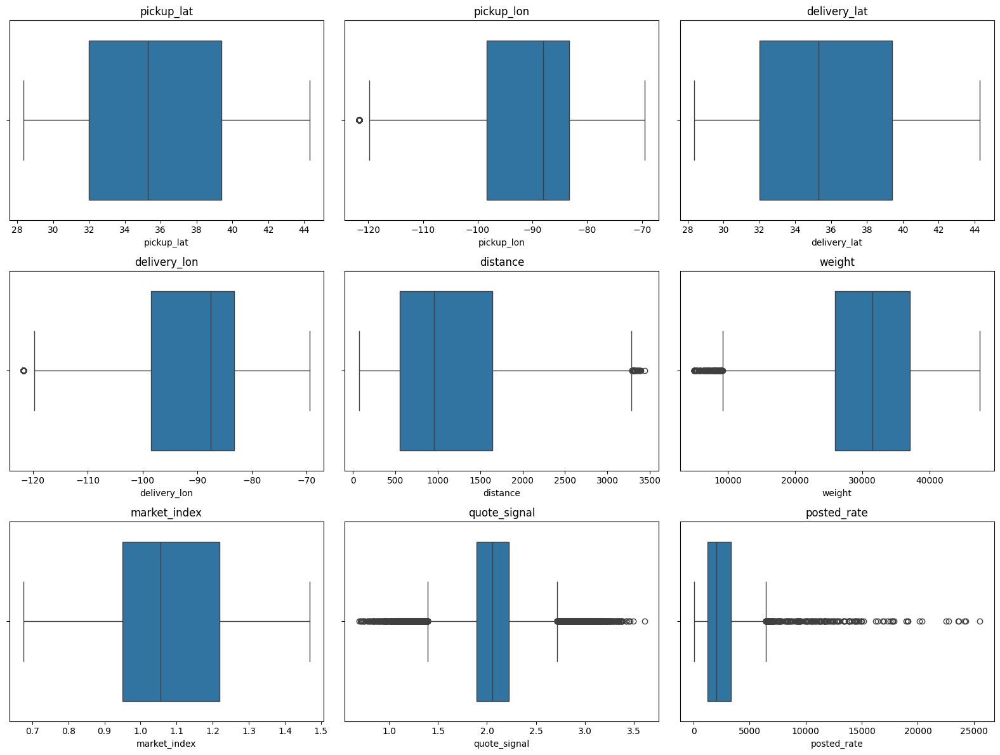

In [124]:
# Boxplots para detectar outliers en cada variable numerica
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 12))
for col, ax in zip(numeric_cols, axes.flatten()):
    sns.boxplot(x=train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Analisis Geografico

Se visualizan las ubicaciones de origen (pickup) y destino (delivery) sobre el mapa de Estados Unidos para entender la cobertura geografica del dataset.

In [125]:
pip install folium


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [126]:
# Mapa interactivo con Plotly: puntos de origen (azul) y destino (rojo)
# Permite identificar las ciudades mas frecuentes y la cobertura geografica
import plotly.graph_objects as go

df_geo = train.dropna(subset=["pickup_lat","pickup_lon","delivery_lat","delivery_lon"]).copy()

fig = go.Figure()
fig.add_trace(go.Scattergeo(
    lat=df_geo["pickup_lat"], lon=df_geo["pickup_lon"],
    mode="markers", name="Pickup",
    marker=dict(size=5, color="royalblue", opacity=0.55),
    customdata=df_geo[["load_id","posted_rate","distance"]].values,
    hovertemplate=("<b>ORIGEN</b><br>Load: %{customdata[0]}<br>"
                   "Rate: %{customdata[1]:,.2f}<br>Distance: %{customdata[2]:,.2f}<extra></extra>")
))
fig.add_trace(go.Scattergeo(
    lat=df_geo["delivery_lat"], lon=df_geo["delivery_lon"],
    mode="markers", name="Delivery",
    marker=dict(size=5, color="crimson", opacity=0.55),
    customdata=df_geo[["load_id","posted_rate","distance"]].values,
    hovertemplate=("<b>DESTINO</b><br>Load: %{customdata[0]}<br>"
                   "Rate: %{customdata[1]:,.2f}<br>Distance: %{customdata[2]:,.2f}<extra></extra>")
))
fig.update_layout(
    title="Distribucion geografica de cargas: Estados Unidos",
    geo=dict(scope="usa", projection_type="albers usa", showland=True,
             landcolor="rgb(235,238,242)", showocean=True, oceancolor="rgb(220,235,245)",
             showsubunits=True, subunitcolor="white"),
    height=750, width=1100, legend=dict(orientation="h", y=1.05)
)
fig.show()

In [127]:
# Mapa de calor con Folium: densidad de cargas por zona geografica
# Las zonas mas rojas concentran mayor numero de cargas
import folium
from folium.plugins import HeatMap
from branca.colormap import LinearColormap

STEP = 0.5

def agrupar(df, lat_col, lon_col, step=STEP):
    return (df.assign(
                lat_bin=(df[lat_col] / step).round() * step,
                lon_bin=(df[lon_col] / step).round() * step)
             .groupby(["lat_bin","lon_bin"]).size()
             .reset_index(name="n_cargas"))

g_pick = agrupar(df_geo, "pickup_lat",   "pickup_lon")
g_deli = agrupar(df_geo, "delivery_lat", "delivery_lon")
vmax   = max(g_pick["n_cargas"].max(), g_deli["n_cargas"].max())

escala = LinearColormap(
    ["#fee5d9","#fcae91","#fb6a4a","#de2d26","#67000d"],
    vmin=1, vmax=vmax, caption="Cantidad de cargas por zona"
)
gradiente_rojo = {0.2:"#fee5d9",0.4:"#fcae91",0.6:"#fb6a4a",0.8:"#de2d26",1.0:"#67000d"}

m = folium.Map(location=[39.5,-98.35], zoom_start=4, tiles=None)
folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}",
    attr="Google Maps", name="Google Maps", max_zoom=20
).add_to(m)

def agregar_capa(g, nombre, visible=True):
    capa = folium.FeatureGroup(name=nombre, show=visible)
    HeatMap(g[["lat_bin","lon_bin","n_cargas"]].values.tolist(),
            radius=22, blur=20, min_opacity=0.35,
            max_val=g["n_cargas"].max(), gradient=gradiente_rojo).add_to(capa)
    total = g["n_cargas"].sum()
    for _, r in g.iterrows():
        pct = r["n_cargas"] / total * 100
        folium.CircleMarker(
            location=[r["lat_bin"],r["lon_bin"]], radius=9,
            color=escala(r["n_cargas"]), weight=1,
            fill=True, fill_color=escala(r["n_cargas"]), fill_opacity=0.15,
            tooltip=folium.Tooltip(
                f"<b>{nombre}</b><br>Cargas: <b>{int(r['n_cargas']):,}</b><br>"
                f"% del total: {pct:.1f}%<br>Lat: {r['lat_bin']:.2f} | Lon: {r['lon_bin']:.2f}"
            )
        ).add_to(capa)
    capa.add_to(m)

agregar_capa(g_pick, "Pickup (origen)",     visible=True)
agregar_capa(g_deli, "Delivery (destino)",  visible=True)
escala.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("mapa_calor_cargas.html")
m

In [128]:
# Red de transporte: muestra 300 rutas aleatorias con origen, destino y trayecto
# Util para identificar corredores de alta densidad de trafico
sample = df_geo.sample(min(300, len(df_geo)), random_state=42)

route_lat, route_lon = [], []
for _, row in sample.iterrows():
    route_lat.extend([row["pickup_lat"],   row["delivery_lat"],   None])
    route_lon.extend([row["pickup_lon"],   row["delivery_lon"],   None])

fig = go.Figure()
fig.add_trace(go.Scattergeo(lat=route_lat, lon=route_lon, mode="lines",
    line=dict(width=0.8, color="gray"), opacity=0.35, name="Rutas"))
fig.add_trace(go.Scattergeo(lat=sample["pickup_lat"], lon=sample["pickup_lon"],
    mode="markers", marker=dict(size=5, color="blue"), name="Pickup"))
fig.add_trace(go.Scattergeo(lat=sample["delivery_lat"], lon=sample["delivery_lon"],
    mode="markers", marker=dict(size=5, color="red"), name="Delivery"))
fig.update_layout(
    title="Red de transporte: 300 rutas de muestra",
    geo=dict(scope="usa", projection_type="albers usa", showland=True,
             landcolor="rgb(235,238,242)", showsubunits=True, subunitcolor="white"),
    height=750, width=1100
)
fig.show()

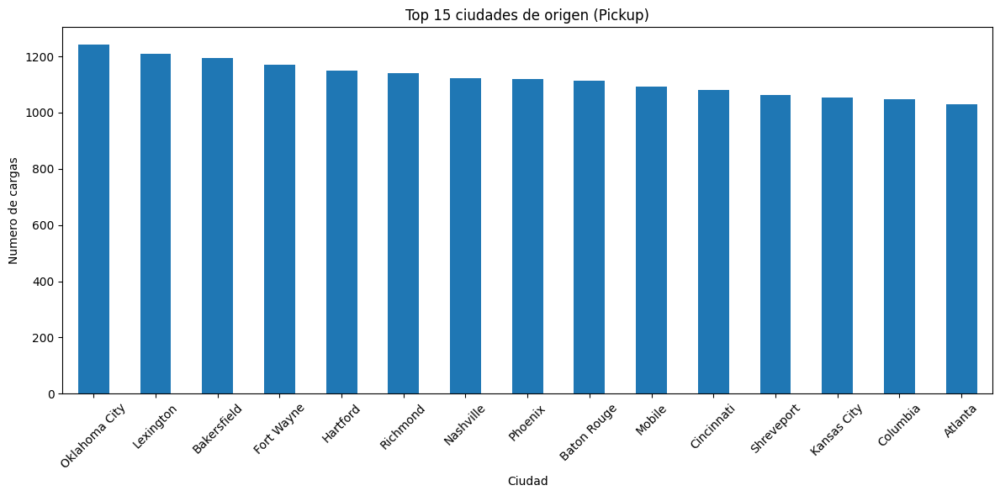

In [129]:
# Top 15 ciudades de origen con mayor volumen de cargas
plt.figure(figsize=(12, 6))
train["pickup"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 ciudades de origen (Pickup)")
plt.xlabel("Ciudad")
plt.ylabel("Numero de cargas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

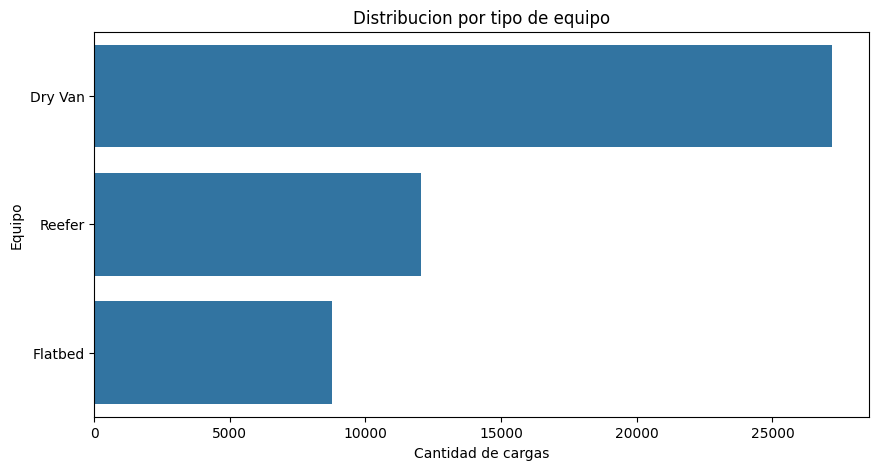

In [130]:
# Distribucion de cargas por tipo de equipo
# Dry Van es el mas frecuente (~57%), seguido de Flatbed y Reefer
plt.figure(figsize=(10, 5))
sns.countplot(data=train, y="equipment",
              order=train["equipment"].value_counts().index)
plt.title("Distribucion por tipo de equipo")
plt.xlabel("Cantidad de cargas")
plt.ylabel("Equipo")
plt.show()

## Analisis de la Variable Objetivo y Senales de Mercado

`posted_rate` es la tarifa publicada (en USD) y es la variable a predecir. `quote_signal` es una senal de cotizacion de mercado que se correlaciona con la tarifa.

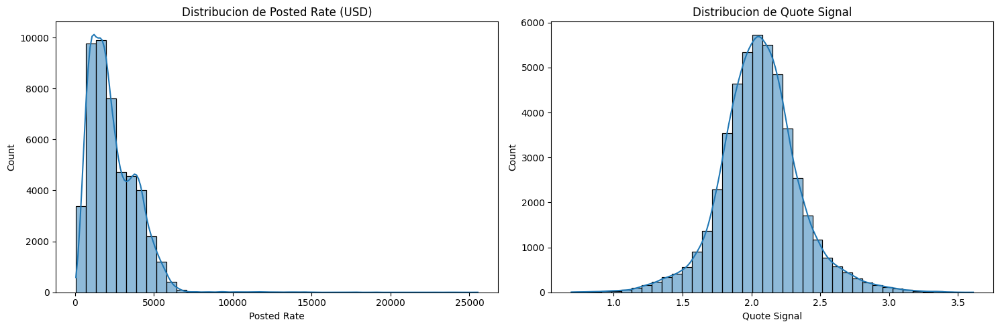

In [131]:
# Distribucion de posted_rate y quote_signal
# posted_rate tiene asimetria positiva fuerte: justifica usar log(rate) como target en el modelo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(train["posted_rate"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribucion de Posted Rate (USD)")
axes[0].set_xlabel("Posted Rate")
sns.histplot(train["quote_signal"].dropna(), bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribucion de Quote Signal")
axes[1].set_xlabel("Quote Signal")
plt.tight_layout()
plt.show()

### Relacion entre Distancia y Tarifa

Se espera una relacion positiva: a mayor distancia, mayor tarifa. La linea de regresion confirma esta tendencia aunque con alta varianza.

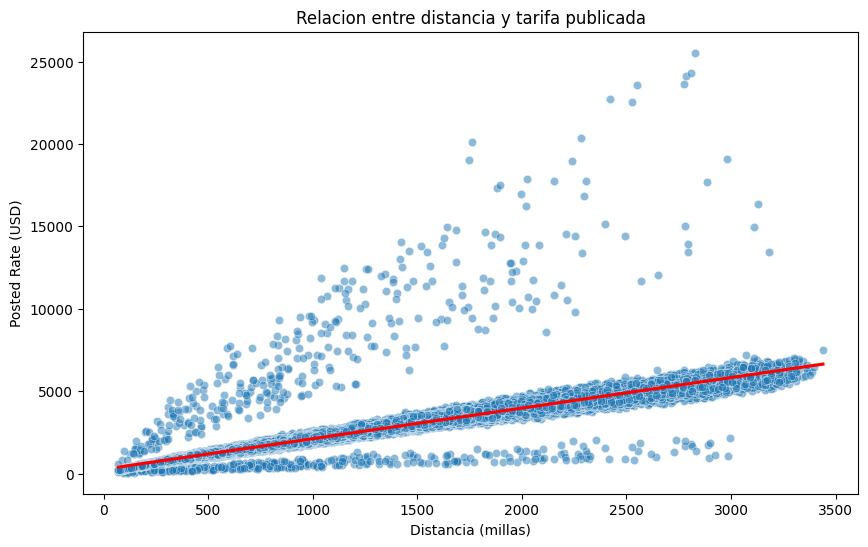

In [132]:
# Relacion lineal entre distancia y tarifa publicada
# La dispersion es alta, lo que indica que la distancia no explica sola la varianza del precio
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x="distance", y="posted_rate", alpha=0.5)
sns.regplot(data=train, x="distance", y="posted_rate", scatter=False, color="red")
plt.title("Relacion entre distancia y tarifa publicada")
plt.xlabel("Distancia (millas)")
plt.ylabel("Posted Rate (USD)")
plt.show()

### Relacion entre Peso, Equipo y Tarifa

Se analiza si el tipo de equipo y el peso de la carga influyen en la tarifa, para detectar interacciones que el modelo deberia capturar.

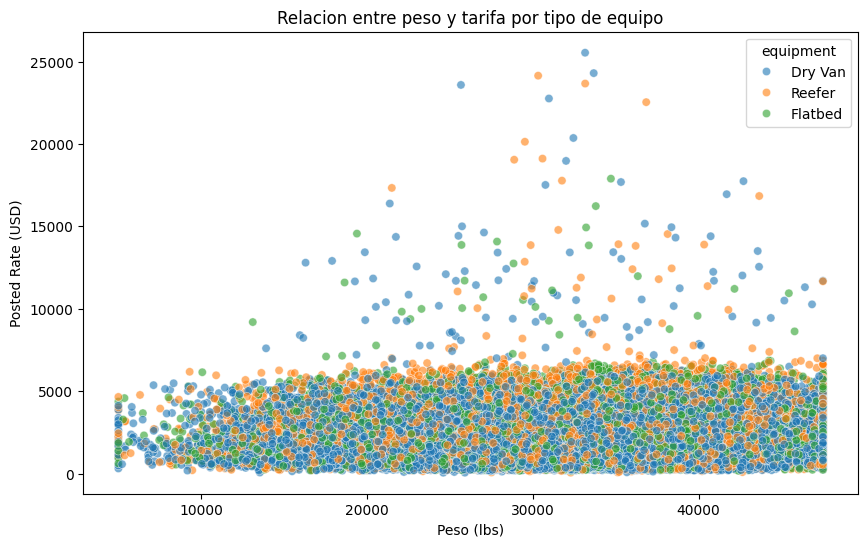

In [133]:
# Scatter de peso vs tarifa segmentado por tipo de equipo
# Flatbed tiende a tarifas mas altas por unidad de peso que Dry Van
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x="weight", y="posted_rate", hue="equipment", alpha=0.6)
plt.title("Relacion entre peso y tarifa por tipo de equipo")
plt.xlabel("Peso (lbs)")
plt.ylabel("Posted Rate (USD)")
plt.show()

In [134]:
# Estadisticas descriptivas ampliadas con percentiles extremos y medidas de forma
# skewness > 0 en posted_rate confirma la necesidad de transformacion logaritmica
variables = ["distance","weight","market_index","quote_signal","posted_rate"]
diagnostico = train[variables].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
diagnostico["skewness"] = train[variables].skew()
diagnostico["kurtosis"] = train[variables].kurtosis()
display(diagnostico.round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
distance,48000.0,1135.857,728.564,70.000,121.899,236.100,550.400,953.300,1645.525,2562.300,3029.304,3439.800,0.766,-0.260
weight,47700.0,31417.249,7996.515,5000.000,12477.980,18005.950,25922.000,31496.000,37063.250,44965.200,47500.000,47500.000,-0.128,-0.296
market_index,47626.0,1.083,0.168,0.676,0.783,0.836,0.950,1.056,1.220,1.366,1.407,1.468,0.214,-1.011
quote_signal,48000.0,2.062,0.291,0.692,1.305,1.606,1.891,2.056,2.222,2.551,2.884,3.610,0.172,1.669
posted_rate,48000.0,2373.981,1486.493,57.220,327.169,599.738,1251.555,2030.760,3330.750,4953.766,5972.834,25533.000,1.902,13.283


### Tarifa por Milla (Rate per Mile)

Normalizar la tarifa por la distancia ayuda a comparar eficiencia de precios entre rutas cortas y largas, y por tipo de equipo.

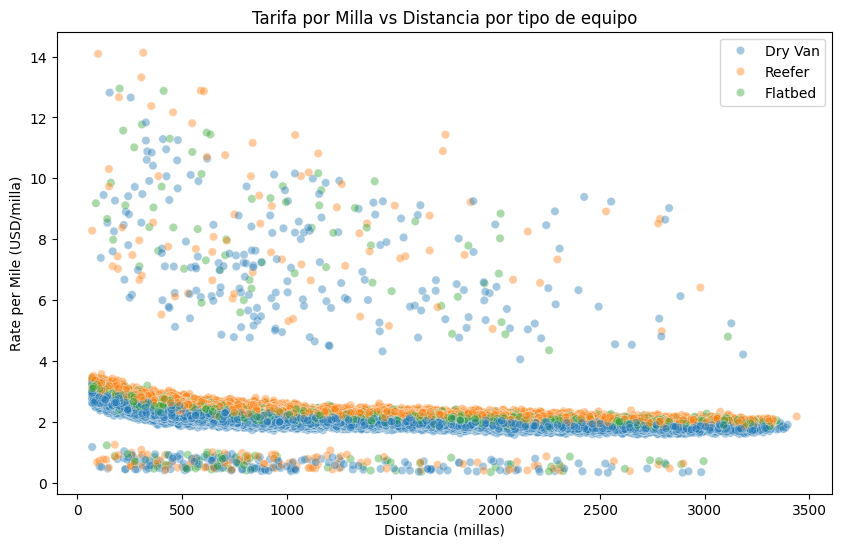

In [135]:
# Calculo y visualizacion de la tarifa por milla (USD/milla)
# Las rutas cortas tienen mayor tarifa por milla (costo fijo de operacion diluido en menos millas)
train["rate_per_mile"] = train["posted_rate"] / train["distance"].replace(0, np.nan)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x="distance", y="rate_per_mile", hue="equipment", alpha=0.4)
plt.title("Tarifa por Milla vs Distancia por tipo de equipo")
plt.xlabel("Distancia (millas)")
plt.ylabel("Rate per Mile (USD/milla)")
plt.legend()
plt.show()

### Comparacion de Tarifas por Tipo de Equipo

Se analizan estadisticas agregadas por equipo para cuantificar las diferencias de tarifa, distancia media y peso promedio entre segmentos.

In [136]:
# Estadisticas agregadas por tipo de equipo
# Flatbed muestra las tarifas medias mas altas y mayor distancia promedio
equipment_comparison = (
    train.groupby("equipment")
    .agg(
        total_loads=("load_id", "count"),
        avg_rate=("posted_rate", "mean"),
        median_rate=("posted_rate", "median"),
        std_rate=("posted_rate", "std"),
        avg_distance=("distance", "mean"),
        median_distance=("distance", "median"),
        avg_weight=("weight", "mean")
    ).round(2)
)
display(equipment_comparison)

,total_loads,avg_rate,median_rate,std_rate,avg_distance,median_distance,avg_weight
equipment,,,,,,,
Dry Van,27202,2271.55,1953.04,1423.03,1137.28,957.55,31389.81
Flatbed,8753,2445.09,2076.81,1505.05,1132.51,940.00,31480.44
Reefer,12045,2553.64,2196.67,1589.67,1135.07,950.20,31433.28


### Tarifa por Rango de Distancia

Segmentar por distancia revela como escala la tarifa y en que rangos hay mayor dispersion (incertidumbre de precio).

In [137]:
# Creacion de grupos de distancia para analisis de tarifa por segmento
# NOTA: esta columna se elimina antes del modelado para evitar data leakage
train["distance_group"] = pd.cut(
    train["distance"],
    bins=[0, 500, 1000, 1500, 2000, 2500, 3000, 4000]
)
distance_analysis = (
    train.groupby("distance_group", observed=True)
    .agg(
        loads=("load_id", "count"),
        mean_rate=("posted_rate", "mean"),
        median_rate=("posted_rate", "median"),
        std_rate=("posted_rate", "std")
    )
)
display(distance_analysis)

,loads,mean_rate,median_rate,std_rate
distance_group,,,,
"(0, 500]",10290,819.909492,834.675,323.619268
"(500, 1000]",15055,1659.697505,1632.280,479.483903
"(1000, 1500]",9008,2584.268010,2515.930,721.080566
"(1500, 2000]",6100,3583.066025,3517.815,888.958872
"(2000, 2500]",4862,4319.928926,4250.650,883.669472
"(2500, 3000]",2116,5204.678214,5106.840,1276.493179
"(3000, 4000]",569,5931.591599,5820.130,797.771408


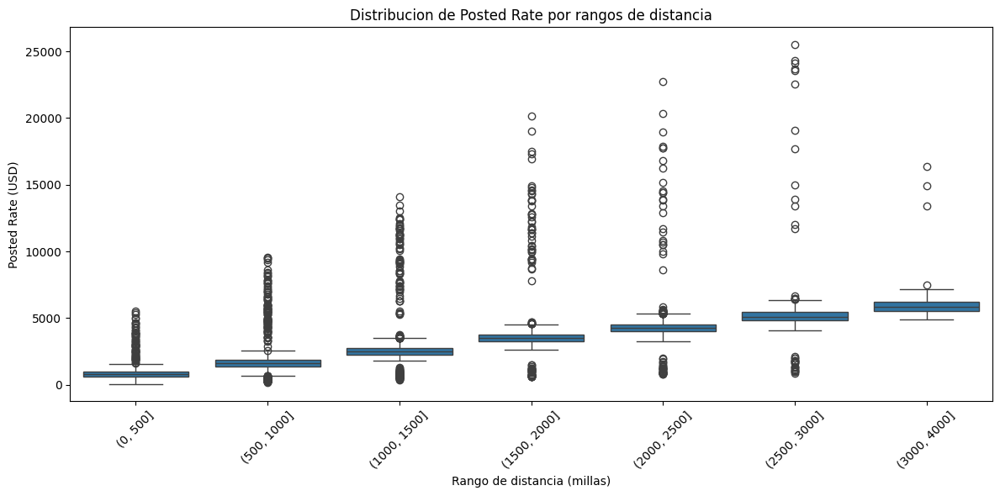

In [138]:
# Boxplot de tarifas por rango de distancia
# La varianza aumenta significativamente en rutas largas (2000+ millas)
plt.figure(figsize=(12, 6))
sns.boxplot(data=train, x="distance_group", y="posted_rate")
plt.title("Distribucion de Posted Rate por rangos de distancia")
plt.xlabel("Rango de distancia (millas)")
plt.ylabel("Posted Rate (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Analisis Temporal

Se analiza si las tarifas presentan estacionalidad mensual. En la industria del transporte, los precios suelen subir en meses de alta demanda (verano, final de ano) y bajar en temporadas bajas.

In [139]:
# Preparacion de serie temporal: agrupacion mensual de tarifas
df_time = train.copy()
df_time["date"] = pd.to_datetime(df_time["date"], errors="coerce")
df_time = df_time.dropna(subset=["date", "posted_rate"]).sort_values("date")

monthly_rate = (
    df_time.set_index("date")
    .resample("MS")["posted_rate"]
    .agg(["median", "mean", "count"])
    .reset_index()
)
display(monthly_rate.head())

,date,median,mean,count
0,2025-01-01,1915.20,2255.967048,4918
1,2025-02-01,1994.25,2273.804801,4337
2,2025-03-01,2022.92,2372.268092,5036
3,2025-04-01,2044.24,2372.162308,4819
4,2025-05-01,2065.51,2421.776342,4913


In [140]:
# Calculo de mediana y media mensual de tarifas para visualizar tendencia
df_time["date"] = pd.to_datetime(df_time["date"], errors="coerce")
df_time = df_time.dropna(subset=["date", "posted_rate"])
monthly_rate = (
    df_time.set_index("date")
    .resample("MS")
    .agg(
        median_rate=("posted_rate", "median"),
        mean_rate=("posted_rate", "mean"),
        operations=("posted_rate", "count")
    )
    .reset_index()
)

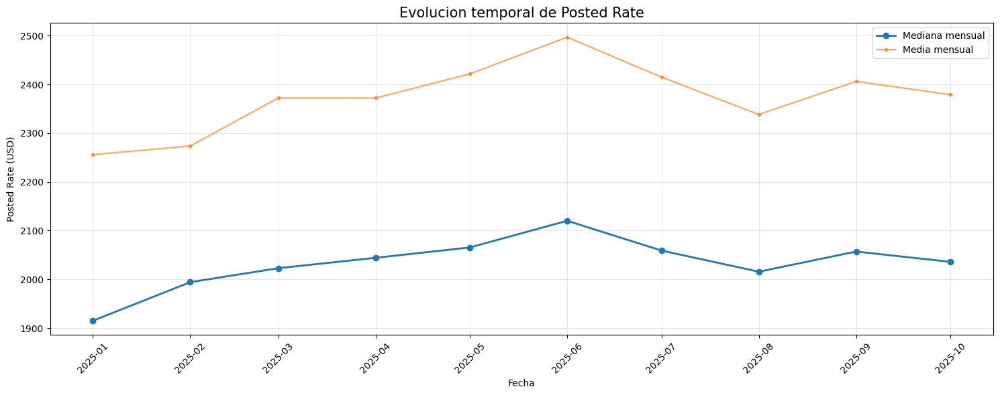

In [141]:
# Evolucion mensual de las tarifas
# Se visualizan media y mediana para distinguir la tendencia central del efecto de outliers
plt.figure(figsize=(15, 6))
plt.plot(monthly_rate["date"], monthly_rate["median_rate"],
         marker="o", linewidth=2, label="Mediana mensual")
plt.plot(monthly_rate["date"], monthly_rate["mean_rate"],
         marker=".", linewidth=1.5, alpha=0.7, label="Media mensual")
plt.title("Evolucion temporal de Posted Rate", fontsize=15)
plt.xlabel("Fecha")
plt.ylabel("Posted Rate (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [142]:
# Calculo mensual conjunto de tarifa y market_index para analizar correlacion temporal
monthly_market = (
    df_time.set_index("date")
    .resample("MS")
    .agg(
        posted_rate_median=("posted_rate", "median"),
        market_index_median=("market_index", "median"),
        operations=("posted_rate", "count")
    )
    .reset_index()
)
display(monthly_market)

,date,posted_rate_median,market_index_median,operations
0,2025-01-01,1915.200,0.932905,4918
1,2025-02-01,1994.250,0.993130,4337
2,2025-03-01,2022.920,1.064850,5036
3,2025-04-01,2044.240,1.207125,4819
4,2025-05-01,2065.510,1.304025,4913
5,2025-06-01,2120.220,1.275130,4783
6,2025-07-01,2059.145,1.212100,4912
7,2025-08-01,2015.730,0.982340,4759
8,2025-09-01,2057.130,0.887810,4670
9,2025-10-01,2035.900,0.958180,4853


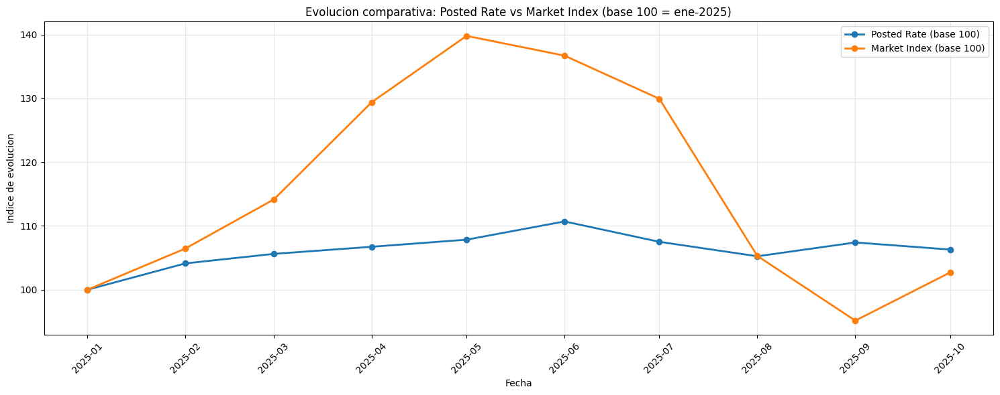

In [143]:
# Comparacion normalizada (base 100) de posted_rate y market_index
# Si ambas curvas siguen tendencias similares, market_index es un buen predictor de tarifa
plt.figure(figsize=(15, 6))
rate_index   = (monthly_market["posted_rate_median"]  / monthly_market["posted_rate_median"].iloc[0])  * 100
market_index = (monthly_market["market_index_median"] / monthly_market["market_index_median"].iloc[0]) * 100
plt.plot(monthly_market["date"], rate_index,   marker="o", linewidth=2, label="Posted Rate (base 100)")
plt.plot(monthly_market["date"], market_index, marker="o", linewidth=2, label="Market Index (base 100)")
plt.title("Evolucion comparativa: Posted Rate vs Market Index (base 100 = ene-2025)")
plt.xlabel("Fecha")
plt.ylabel("Indice de evolucion")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
# Modelado Predictivo

El objetivo es predecir `posted_rate` a partir de las caracteristicas de cada carga. Se sigue una estrategia incremental:

1. **Preparacion de datos**: limpieza, imputacion y feature engineering
2. **Modelos base**: Regresion Lineal, Random Forest
3. **Gradient Boosting**: XGBoost y LightGBM con transformacion logaritmica del target
4. **Busqueda de hiperparametros**: Optuna (optimizacion bayesiana)
5. **Red neuronal (MLP)**: arquitectura densa con PyTorch o sklearn
6. **Stacking Ensemble**: combinacion de todos los modelos
7. **Prediccion final**: aplicacion sobre el set de validacion

In [144]:
# Importaciones necesarias para el pipeline de modelado
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import warnings
warnings.filterwarnings("ignore")

## Preparacion del Dataset para Modelado

**Correcciones aplicadas sobre el modelo original:**
- `distance_group` y `rate_per_mile` se eliminan (son derivadas de EDA que causarian data leakage si entraran al modelo).
- `quote_signal` se **conserva** (el modelo original la descartaba incorrectamente; es una senal de mercado relevante).
- `weight_sign_corrected` se mantiene como feature binaria.
- `market_index_missing` se propaga correctamente hasta el modelo.
- Se corrige el bug `NameError: df_equipment` de la celda de correlacion original.

In [145]:
# Eliminar columnas creadas durante el EDA que no deben entrar al modelo
cols_eda_only = ["rate_per_mile", "distance_group"]
train_clean = train.drop(
    columns=[c for c in cols_eda_only if c in train.columns]
).copy()

# Corregir signo de weight (mismo proceso que en EDA pero sobre train_clean)
train_clean["weight_sign_corrected"] = (train_clean["weight"] < 0).astype(int)
train_clean["weight"] = train_clean["weight"].abs()

# Correccion del NameError original: df_equipment no estaba definido
df_equipment = train_clean.copy()
correlation_equipment = df_equipment.groupby("equipment").apply(
    lambda g: g["distance"].corr(g["posted_rate"]), include_groups=False
)
print("Correlacion distancia-tarifa por tipo de equipo:")
display(correlation_equipment.to_frame(name="correlation_distance_rate"))

Correlacion distancia-tarifa por tipo de equipo:


,correlation_distance_rate
equipment,
Dry Van,0.908766
Flatbed,0.926035
Reefer,0.912005


In [146]:
# Division train/test estratificada temporalmente (80/20)
# Se usa random_state=42 para reproducibilidad
X = train_clean.drop(columns=["posted_rate"])
y = train_clean["posted_rate"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (38400, 14) | X_test: (9600, 14)


### Imputacion de Valores Faltantes

Se usa la **mediana** del set de entrenamiento para imputar `weight` y `market_index`. El imputador se ajusta **solo** sobre el train para evitar data leakage hacia el test.

In [147]:
# Imputacion con mediana: robusta frente a outliers y distribuciones asimetricas
# fit_transform en train, solo transform en test (mismo criterio se aplica a validacion)
columns_to_impute = ["weight", "market_index"]
imputer = SimpleImputer(strategy="median")

X_train[columns_to_impute] = imputer.fit_transform(X_train[columns_to_impute])
X_test[columns_to_impute]  = imputer.transform(X_test[columns_to_impute])

# Flag binario: indica si market_index fue imputado (puede ser informativo para el modelo)
X_train["market_index_missing"] = (
    train_clean.loc[X_train.index, "market_index"].isna().astype(int)
)
X_test["market_index_missing"] = (
    train_clean.loc[X_test.index, "market_index"].isna().astype(int)
)
print("Nulos tras imputacion:")
print(X_train[columns_to_impute].isnull().sum())

Nulos tras imputacion:
weight          0
market_index    0
dtype: int64


### Feature Engineering

Se crean nuevas variables para enriquecer la representacion de cada carga:

| Feature | Descripcion |
|---|---|
| `bearing` | Direccion del viaje en grados (0-360°). Captura tendencias N/S/E/W |
| `delta_lat`, `delta_lon` | Diferencias absolutas de coordenadas |
| `haversine_km` | Distancia geografica real calculada con la formula haversine |
| `dist_x_market` | Distancia × market_index (interaccion de mercado) |
| `dist_x_quote` | Distancia × quote_signal (efecto combinado) |
| `quote_x_market` | quote_signal × market_index |
| `dist_dry_van/flatbed/reefer` | Distancia especifica por tipo de equipo |
| `month`, `quarter`, `day_of_week`, `day_of_year` | Variables temporales desde la fecha |

In [148]:
def add_features(df, source_df):
    """
    Genera features de ingenieria a partir del dataframe de entrada.
    source_df: dataframe original que contiene las columnas "date" y "quote_signal"
    (necesario porque df puede ser un subconjunto sin esas columnas).
    """
    df = df.copy()

    # ── Variables temporales ────────────────────────────────────────────────
    dates = pd.to_datetime(source_df.loc[df.index, "date"], errors="coerce")
    df["month"]       = dates.dt.month        # Estacionalidad mensual
    df["quarter"]     = dates.dt.quarter      # Estacionalidad trimestral
    df["day_of_week"] = dates.dt.dayofweek    # Efecto dia de la semana (0=lunes)
    df["day_of_year"] = dates.dt.dayofyear    # Posicion en el ano

    # ── Variables geoespaciales ─────────────────────────────────────────────
    df["delta_lat"] = (df["delivery_lat"] - df["pickup_lat"]).abs()
    df["delta_lon"] = (df["delivery_lon"] - df["pickup_lon"]).abs()

    # Bearing: angulo de la ruta respecto al norte (0=Norte, 90=Este, etc.)
    lat1 = np.radians(df["pickup_lat"])
    lat2 = np.radians(df["delivery_lat"])
    dlon = np.radians(df["delivery_lon"] - df["pickup_lon"])
    x    = np.sin(dlon) * np.cos(lat2)
    yy   = np.cos(lat1)*np.sin(lat2) - np.sin(lat1)*np.cos(lat2)*np.cos(dlon)
    df["bearing"] = np.degrees(np.arctan2(x, yy)) % 360

    # Distancia haversine en km (independiente de la columna "distance" del dataset)
    R    = 6371
    phi1 = np.radians(df["pickup_lat"])
    phi2 = np.radians(df["delivery_lat"])
    dphi = phi2 - phi1
    dlam = np.radians(df["delivery_lon"] - df["pickup_lon"])
    a_hav = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlam/2)**2
    df["haversine_km"] = 2 * R * np.arcsin(np.sqrt(a_hav.clip(0, 1)))

    # ── Interacciones multiplicativas ───────────────────────────────────────
    qs = source_df.loc[df.index, "quote_signal"].values
    df["dist_x_market"]  = df["distance"] * df["market_index"]  # Efecto distancia x mercado
    df["dist_x_quote"]   = df["distance"] * qs                  # Efecto distancia x senal
    df["quote_x_market"] = qs * df["market_index"]              # Senal x indice de mercado

    # Interaccion distancia x equipo: captura que cada tipo escala distinto con la distancia
    for eq in ["Dry Van", "Flatbed", "Reefer"]:
        col = "dist_" + eq.lower().replace(" ", "_")
        df[col] = df["distance"] * (df["equipment"] == eq).astype(int)

    return df


X_train_fe = add_features(X_train, train_clean)
X_test_fe  = add_features(X_test,  train_clean)
print("Shape con features:", X_train_fe.shape)

Shape con features: (38400, 29)


In [149]:
# Eliminar columnas identificadoras y de fecha (no aportan como features numericas)
cols_to_drop_model = ["load_id", "date"]
X_tr = X_train_fe.drop(
    columns=[c for c in cols_to_drop_model if c in X_train_fe.columns]
).copy()
X_te = X_test_fe.drop(
    columns=[c for c in cols_to_drop_model if c in X_test_fe.columns]
).copy()

# Separar variables categoricas y numericas para el pipeline de preprocesamiento
cat_cols = X_tr.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_tr.select_dtypes(include="number").columns.tolist()

print("Variables categoricas:", cat_cols)
print("Variables numericas:", num_cols)

Variables categoricas: ['pickup', 'delivery', 'equipment']
Variables numericas: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'weight_sign_corrected', 'market_index_missing', 'month', 'quarter', 'day_of_week', 'day_of_year', 'delta_lat', 'delta_lon', 'bearing', 'haversine_km', 'dist_x_market', 'dist_x_quote', 'quote_x_market', 'dist_dry_van', 'dist_flatbed', 'dist_reefer']


In [150]:
# Preprocesador: estandariza numericas (media 0, std 1) y codifica categoricas con OHE
# handle_unknown="ignore": si aparece una categoria nueva en test/validacion, se ignora
preprocessor_v2 = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

### Modelo Baseline: Regresion Lineal

Se entrena como punto de referencia para cuantificar el beneficio de modelos mas complejos.

In [151]:
# Regresion Lineal: modelo baseline
# Sirve como punto de referencia; se espera R2 bajo por la no-linealidad del problema
model_lr = Pipeline([("pre", preprocessor_v2), ("reg", LinearRegression())])
model_lr.fit(X_tr, y_train)
y_pred_lr = model_lr.predict(X_te)
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr   = r2_score(y_test, y_pred_lr)
print("LR   MAE:", round(mae_lr,2), " RMSE:", round(rmse_lr,2), " R2:", round(r2_lr,4))

LR   MAE: 114.88  RMSE: 530.26  R2: 0.8685


### Random Forest

Modelo de ensamble basado en bagging de arboles de decision. Captura relaciones no lineales y es robusto frente a outliers.

In [152]:
# Random Forest con 300 arboles
# min_samples_leaf=2 reduce el overfitting en nodos hoja
model_rf = Pipeline([
    ("pre", preprocessor_v2),
    ("reg", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ))
])
model_rf.fit(X_tr, y_train)
y_pred_rf = model_rf.predict(X_te)
mae_rf  = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf   = r2_score(y_test, y_pred_rf)
print("RF   MAE:", round(mae_rf,2), " RMSE:", round(rmse_rf,2), " R2:", round(r2_rf,4))

RF   MAE: 121.22  RMSE: 552.51  R2: 0.8573


### XGBoost

Gradient Boosting con regularizacion L1/L2. Se entrena sobre `log1p(posted_rate)` para reducir la asimetria del target y mejorar la precision en valores pequenos.

In [153]:
try:
    from xgboost import XGBRegressor
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    from xgboost import XGBRegressor

# Transformacion logaritmica del target: reduce asimetria y mejora el ajuste en valores bajos
y_train_log = np.log1p(y_train)

model_xgb = Pipeline([
    ("pre", preprocessor_v2),
    ("reg", XGBRegressor(
        n_estimators=1000, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, n_jobs=-1, verbosity=0
    ))
])
model_xgb.fit(X_tr, y_train_log)
# Deshacer la transformacion logaritmica para obtener predicciones en USD
y_pred_xgb = np.expm1(model_xgb.predict(X_te))

mae_xgb  = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb   = r2_score(y_test, y_pred_xgb)
print("XGB  MAE:", round(mae_xgb,2), " RMSE:", round(rmse_xgb,2), " R2:", round(r2_xgb,4))

XGB  MAE: 117.82  RMSE: 539.77  R2: 0.8638


### LightGBM

Alternativa a XGBoost: mas rapido en entrenamiento y con soporte nativo para variables categoricas. Suele alcanzar resultados comparables o superiores en datasets tabulares de tamano mediano.

In [154]:
try:
    from lightgbm import LGBMRegressor
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lightgbm", "-q"])
    from lightgbm import LGBMRegressor

# LightGBM con num_leaves=63: mayor capacidad de capturar relaciones complejas
model_lgbm = Pipeline([
    ("pre", preprocessor_v2),
    ("reg", LGBMRegressor(
        n_estimators=1000, learning_rate=0.05, max_depth=6, num_leaves=63,
        subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, n_jobs=-1, verbose=-1
    ))
])
model_lgbm.fit(X_tr, y_train_log)
y_pred_lgbm = np.expm1(model_lgbm.predict(X_te))

mae_lgbm  = mean_absolute_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))
r2_lgbm   = r2_score(y_test, y_pred_lgbm)
print("LGBM MAE:", round(mae_lgbm,2), " RMSE:", round(rmse_lgbm,2), " R2:", round(r2_lgbm,4))

LGBM MAE: 112.29  RMSE: 535.23  R2: 0.8661


### Comparacion de modelos base

In [155]:
# Tabla comparativa de los cuatro modelos base
models_results = {
    "Linear Regression": y_pred_lr,
    "Random Forest":     y_pred_rf,
    "XGBoost (log)":     y_pred_xgb,
    "LightGBM (log)":    y_pred_lgbm,
}
rows = []
for name, preds in models_results.items():
    rows.append({
        "Model": name,
        "MAE":  round(mean_absolute_error(y_test, preds), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, preds)), 2),
        "R2":   round(r2_score(y_test, preds), 4)
    })
comparison_df = pd.DataFrame(rows).sort_values("R2", ascending=False)
display(comparison_df)

,Model,MAE,RMSE,R2
0,Linear Regression,114.88,530.26,0.8685
3,LightGBM (log),112.29,535.23,0.8661
2,XGBoost (log),117.82,539.77,0.8638
1,Random Forest,121.22,552.51,0.8573


### Importancia de Variables - XGBoost

El grafico muestra las 20 variables mas importantes segun XGBoost. Las features de interaccion (distancia x equipo, distancia x mercado) suelen aparecer entre las primeras.

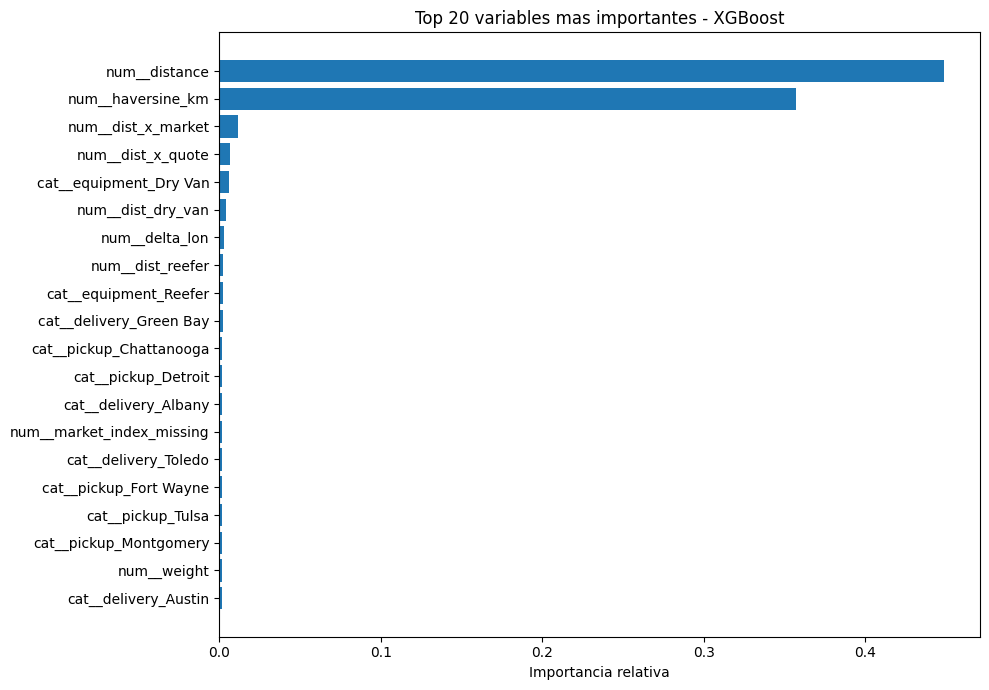

In [156]:
# Importancia de variables segun XGBoost (gain-based feature importance)
xgb_step = model_xgb.named_steps["reg"]
pre_step  = model_xgb.named_steps["pre"]
feature_names_out = pre_step.get_feature_names_out()
importances       = xgb_step.feature_importances_

fi_df = (
    pd.DataFrame({"feature": feature_names_out, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(20)
)
plt.figure(figsize=(10, 7))
plt.barh(fi_df["feature"][::-1], fi_df["importance"][::-1])
plt.title("Top 20 variables mas importantes - XGBoost")
plt.xlabel("Importancia relativa")
plt.tight_layout()
plt.show()

### Analisis de Residuos - XGBoost

El grafico Real vs Predicho debe alinearse con la diagonal (prediccion perfecta). La distribucion de errores debe ser centrada en 0 y lo mas simetrica posible.

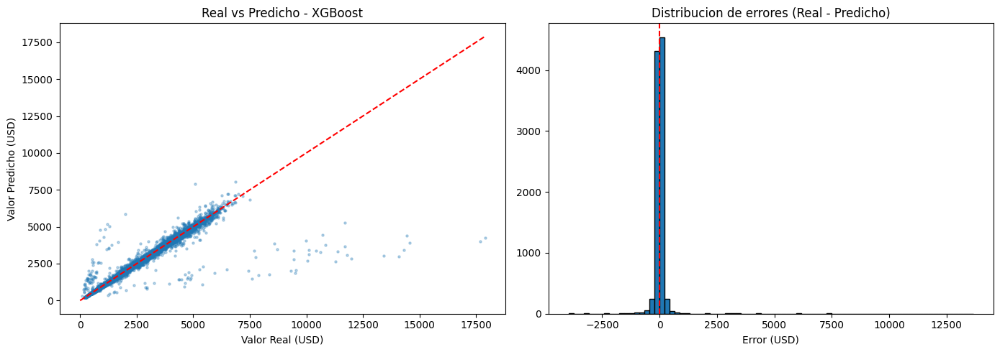

In [157]:
# Diagnostico de residuos para evaluar calidad del ajuste de XGBoost
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafico 1: Real vs Predicho (ideal: puntos sobre la linea roja)
axes[0].scatter(y_test, y_pred_xgb, alpha=0.3, s=5)
lim = max(float(y_test.max()), float(y_pred_xgb.max()))
axes[0].plot([0, lim], [0, lim], "r--")
axes[0].set_xlabel("Valor Real (USD)")
axes[0].set_ylabel("Valor Predicho (USD)")
axes[0].set_title("Real vs Predicho - XGBoost")

# Grafico 2: Distribucion de errores (ideal: campana centrada en 0)
residuals = y_test.values - y_pred_xgb
axes[1].hist(residuals, bins=80, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribucion de errores (Real - Predicho)")
axes[1].set_xlabel("Error (USD)")

plt.tight_layout()
plt.show()

### Prediccion inicial sobre Validacion (XGBoost base)

Resultado preliminar antes de las estrategias avanzadas. Se mejorara con Optuna, red neuronal y stacking en la siguiente seccion.

In [158]:
# Prediccion preliminar sobre validacion con XGBoost base (sin tuning)
val_clean = validation.copy()
val_clean["weight_sign_corrected"] = (val_clean["weight"].fillna(0) < 0).astype(int)
val_clean["weight"] = val_clean["weight"].abs()
for col, med in zip(columns_to_impute, imputer.statistics_):
    val_clean[col] = val_clean[col].fillna(med)
val_clean["market_index_missing"] = validation["market_index"].isna().astype(int)

val_fe = add_features(val_clean, val_clean)
val_fe = val_fe.drop(columns=[c for c in cols_to_drop_model if c in val_fe.columns])

val_pred = np.expm1(model_xgb.predict(val_fe))
print("Predicciones XGB base sobre validacion - estadisticas:")
print(pd.Series(val_pred).describe().round(2))

Predicciones XGB base sobre validacion - estadisticas:
count    12000.00
mean      2371.87
std       1415.47
min        167.71
25%       1269.51
50%       2012.69
75%       3379.88
max       8478.57
dtype: float64


---
# Estrategias Avanzadas para Alcanzar R² >= 0.92

Se aplican tres estrategias adicionales sobre el pipeline existente:

1. **XGBoost + Optuna**: busqueda bayesiana de hiperparametros (50 trials, CV-3)
2. **Red Neuronal MLP**: arquitectura densa con BatchNorm y Dropout (PyTorch o sklearn)
3. **LightGBM + Optuna**: busqueda bayesiana especifica para LightGBM
4. **Stacking Ensemble**: combina los mejores modelos con out-of-fold predictions

## 1. XGBoost + Optuna (Busqueda Bayesiana de Hiperparametros)

Optuna minimiza el RMSE en validacion cruzada (3-fold) explorando el espacio de hiperparametros de forma inteligente (TPE sampler). 50 trials en espacio log para `learning_rate` y regularizacion.

In [159]:
# Instalar Optuna si no esta disponible
try:
    import optuna
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Pre-procesar las matrices una sola vez para acelerar la busqueda (no reprocesar en cada trial)
X_tr_pre = preprocessor_v2.fit_transform(X_tr)
X_te_pre = preprocessor_v2.transform(X_te)
y_log    = np.log1p(y_train)

def objective(trial):
    """Funcion objetivo de Optuna: retorna RMSE en espacio log (CV-3)."""
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 400, 1500),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "max_depth":         trial.suggest_int("max_depth", 4, 9),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "random_state": 42, "n_jobs": -1, "verbosity": 0
    }
    model = XGBRegressor(**params)
    scores = cross_val_score(
        model, X_tr_pre, y_log,
        cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    return -scores.mean()  # Optuna minimiza, por eso negamos el RMSE negativo

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50, show_progress_bar=False)

print("Mejores hiperparametros encontrados por Optuna (XGBoost):")
print(study.best_params)

Mejores hiperparametros encontrados por Optuna (XGBoost):
{'n_estimators': 629, 'learning_rate': 0.01593773132369005, 'max_depth': 4, 'subsample': 0.7081525806021486, 'colsample_bytree': 0.998311855829529, 'min_child_weight': 4, 'reg_alpha': 2.4577577499972842, 'reg_lambda': 0.0002180253602228567}


In [160]:
# Entrenar XGBoost con los hiperparametros optimos encontrados por Optuna
best_params = study.best_params
best_params.update({"random_state": 42, "n_jobs": -1, "verbosity": 0})

xgb_tuned = XGBRegressor(**best_params)
xgb_tuned.fit(X_tr_pre, y_log)

y_pred_xgb_tuned = np.expm1(xgb_tuned.predict(X_te_pre))

mae_xt  = mean_absolute_error(y_test, y_pred_xgb_tuned)
rmse_xt = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned))
r2_xt   = r2_score(y_test, y_pred_xgb_tuned)
print("XGB-Tuned  MAE:", round(mae_xt,2), " RMSE:", round(rmse_xt,2), " R2:", round(r2_xt,4))

XGB-Tuned  MAE: 90.9  RMSE: 526.63  R2: 0.8703


## 2. Red Neuronal MLP

**Arquitectura (PyTorch):** 4 capas densas con BatchNorm + Dropout, optimizador Adam con weight decay, scheduler coseno (80 epocas).

**Fallback (sklearn):** `MLPRegressor` con early stopping si PyTorch no esta disponible.

El target sigue siendo `log1p(posted_rate)` para consistencia con los demas modelos.

In [161]:
# Red Neuronal: PyTorch si disponible, MLPRegressor como fallback
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch no disponible, se usara MLPRegressor de sklearn")

if TORCH_AVAILABLE:
    class RateNet(nn.Module):
        """Red neuronal para regresion de tarifas de transporte.
        Arquitectura: 512 -> 256 -> 128 -> 64 -> 1 con BatchNorm y Dropout.
        """
        def __init__(self, in_dim):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(in_dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
                nn.Linear(512, 256),   nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
                nn.Linear(256, 128),   nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.1),
                nn.Linear(128, 64),    nn.ReLU(),
                nn.Linear(64, 1)
            )
        def forward(self, x):
            return self.net(x).squeeze(1)

    X_tr_t = torch.tensor(X_tr_pre.astype("float32"))
    y_tr_t = torch.tensor(np.log1p(y_train.values).astype("float32"))
    X_te_t = torch.tensor(X_te_pre.astype("float32"))

    loader  = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=1024, shuffle=True)
    device  = "cuda" if torch.cuda.is_available() else "cpu"
    net     = RateNet(X_tr_t.shape[1]).to(device)
    opt     = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    sched   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=80)
    loss_fn = nn.MSELoss()

    net.train()
    for epoch in range(80):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(net(xb), yb).backward()
            opt.step()
        sched.step()
        if (epoch+1) % 20 == 0:
            print(f"  Epoca {epoch+1}/80 completada")

    net.eval()
    with torch.no_grad():
        y_pred_nn_log = net(X_te_t.to(device)).cpu().numpy()
    y_pred_nn = np.expm1(y_pred_nn_log)

else:
    # Fallback: MLPRegressor de sklearn
    from sklearn.neural_network import MLPRegressor
    mlp = MLPRegressor(
        hidden_layer_sizes=(512, 256, 128, 64),
        activation="relu", learning_rate_init=1e-3,
        max_iter=200, early_stopping=True,
        validation_fraction=0.1, random_state=42
    )
    mlp.fit(X_tr_pre, np.log1p(y_train))
    y_pred_nn = np.expm1(mlp.predict(X_te_pre))

mae_nn  = mean_absolute_error(y_test, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
r2_nn   = r2_score(y_test, y_pred_nn)
print("MLP/NN  MAE:", round(mae_nn,2), " RMSE:", round(rmse_nn,2), " R2:", round(r2_nn,4))

  Epoca 20/80 completada
  Epoca 40/80 completada
  Epoca 60/80 completada
  Epoca 80/80 completada
MLP/NN  MAE: 121.85  RMSE: 532.59  R2: 0.8674


## 3. LightGBM + Optuna

Busqueda bayesiana con 50 trials especifica para LightGBM. `num_leaves` hasta 255 permite arboles mas profundos que capturan interacciones complejas sin el costo de `max_depth` explicito.

In [162]:
from lightgbm import LGBMRegressor

def objective_lgbm(trial):
    """Funcion objetivo de Optuna para LightGBM."""
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 400, 2000),
        "learning_rate":     trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 31, 255),
        "max_depth":         trial.suggest_int("max_depth", 4, 10),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "random_state": 42, "n_jobs": -1, "verbose": -1
    }
    model = LGBMRegressor(**params)
    scores = cross_val_score(
        model, X_tr_pre, y_log,
        cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    return -scores.mean()

study_lgbm = optuna.create_study(direction="minimize")
study_lgbm.optimize(objective_lgbm, n_trials=50, show_progress_bar=False)

# Entrenar con los mejores hiperparametros encontrados
best_lgbm_params = study_lgbm.best_params
best_lgbm_params.update({"random_state": 42, "n_jobs": -1, "verbose": -1})

lgbm_tuned = LGBMRegressor(**best_lgbm_params)
lgbm_tuned.fit(X_tr_pre, y_log)

y_pred_lgbm_tuned = np.expm1(lgbm_tuned.predict(X_te_pre))

mae_lt  = mean_absolute_error(y_test, y_pred_lgbm_tuned)
rmse_lt = np.sqrt(mean_squared_error(y_test, y_pred_lgbm_tuned))
r2_lt   = r2_score(y_test, y_pred_lgbm_tuned)
print("LGBM-Tuned  MAE:", round(mae_lt,2), " RMSE:", round(rmse_lt,2), " R2:", round(r2_lt,4))

LGBM-Tuned  MAE: 91.89  RMSE: 527.09  R2: 0.8701


## 4. Stacking Ensemble

Combina las predicciones de XGBoost-Tuned, LightGBM-Tuned, Random Forest y la red neuronal usando Ridge como meta-modelo.

**Por que stacking supera a los modelos individuales:**
Cada modelo captura diferentes patrones. El meta-modelo aprende a ponderar las fortalezas de cada uno segun el tipo de instancia.

**Tecnica out-of-fold (OOF):** se generan predicciones en datos no vistos durante el entrenamiento de cada fold, evitando que el meta-modelo vea predicciones del mismo conjunto con el que se entreno (data leakage).

In [163]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge

# 5-fold cross-validation para generar out-of-fold predictions
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Base learners: XGBoost-Tuned, LightGBM-Tuned y Random Forest
base_learners = {
    "xgb_t":  XGBRegressor(**best_params),
    "lgbm_t": LGBMRegressor(**best_lgbm_params),
    "rf":     RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                    random_state=42, n_jobs=-1),
}

# Matrices para almacenar las predicciones OOF (train) y promediadas (test)
oof_train = np.zeros((X_tr_pre.shape[0], len(base_learners)))
oof_test  = np.zeros((X_te_pre.shape[0], len(base_learners)))

for j, (name, learner) in enumerate(base_learners.items()):
    test_preds_folds = np.zeros((X_te_pre.shape[0], kf.n_splits))
    for fold_idx, (tr_idx, val_idx) in enumerate(kf.split(X_tr_pre)):
        # Entrenar en el fold de entrenamiento
        learner.fit(X_tr_pre[tr_idx], y_log.iloc[tr_idx])
        # Prediccion OOF para el meta-modelo
        oof_train[val_idx, j] = learner.predict(X_tr_pre[val_idx])
        # Prediccion en test para este fold
        test_preds_folds[:, fold_idx] = learner.predict(X_te_pre)
    # Promediar predicciones de test sobre todos los folds
    oof_test[:, j] = test_preds_folds.mean(axis=1)
    print(f"  {name}: folds completados")

print("OOF train shape:", oof_train.shape, "| OOF test shape:", oof_test.shape)

  xgb_t: folds completados
  lgbm_t: folds completados
  rf: folds completados
OOF train shape: (38400, 3) | OOF test shape: (9600, 3)


In [164]:
# Agregar las predicciones OOF de la red neuronal al stack
# Esto agrega una columna mas al meta-modelo con un tipo de modelo completamente diferente
if TORCH_AVAILABLE:
    nn_oof_tr = np.zeros(X_tr_pre.shape[0])
    nn_oof_te_folds = np.zeros((X_te_pre.shape[0], kf.n_splits))
    for fold_idx, (tr_idx, val_idx) in enumerate(kf.split(X_tr_pre)):
        Xf_tr  = torch.tensor(X_tr_pre[tr_idx].astype("float32"))
        yf_tr  = torch.tensor(y_log.iloc[tr_idx].values.astype("float32"))
        Xf_val = torch.tensor(X_tr_pre[val_idx].astype("float32"))
        Xf_te  = torch.tensor(X_te_pre.astype("float32"))
        net_f  = RateNet(Xf_tr.shape[1]).to(device)
        opt_f  = torch.optim.Adam(net_f.parameters(), lr=1e-3, weight_decay=1e-4)
        ld_f   = DataLoader(TensorDataset(Xf_tr, yf_tr), batch_size=1024, shuffle=True)
        net_f.train()
        for _ in range(60):
            for xb, yb in ld_f:
                xb, yb = xb.to(device), yb.to(device)
                opt_f.zero_grad()
                loss_fn(net_f(xb), yb).backward()
                opt_f.step()
        net_f.eval()
        with torch.no_grad():
            nn_oof_tr[val_idx] = net_f(Xf_val.to(device)).cpu().numpy()
            nn_oof_te_folds[:, fold_idx] = net_f(Xf_te.to(device)).cpu().numpy()
        print(f"  Red neuronal fold {fold_idx+1}/5 completado")
    oof_train_full = np.column_stack([oof_train, nn_oof_tr])
    oof_test_full  = np.column_stack([oof_test,  nn_oof_te_folds.mean(axis=1)])
else:
    # Fallback: agregar MLPRegressor al stack
    nn_oof_tr_sk = np.zeros(X_tr_pre.shape[0])
    nn_oof_te_sk_folds = np.zeros((X_te_pre.shape[0], kf.n_splits))
    for fold_idx, (tr_idx, val_idx) in enumerate(kf.split(X_tr_pre)):
        mlp_f = MLPRegressor(hidden_layer_sizes=(512,256,128,64), activation="relu",
                             learning_rate_init=1e-3, max_iter=200, random_state=42)
        mlp_f.fit(X_tr_pre[tr_idx], y_log.iloc[tr_idx])
        nn_oof_tr_sk[val_idx] = mlp_f.predict(X_tr_pre[val_idx])
        nn_oof_te_sk_folds[:, fold_idx] = mlp_f.predict(X_te_pre)
        print(f"  MLP sklearn fold {fold_idx+1}/5 completado")
    oof_train_full = np.column_stack([oof_train, nn_oof_tr_sk])
    oof_test_full  = np.column_stack([oof_test,  nn_oof_te_sk_folds.mean(axis=1)])

print("Stack con NN - shape:", oof_train_full.shape)

  Red neuronal fold 1/5 completado
  Red neuronal fold 2/5 completado
  Red neuronal fold 3/5 completado
  Red neuronal fold 4/5 completado
  Red neuronal fold 5/5 completado
Stack con NN - shape: (38400, 4)


In [165]:
# Meta-modelo: Ridge en espacio log
# Ridge es preferible a OLS para el meta-modelo porque controla la colinealidad
# entre las predicciones de los base learners (que suelen estar correlacionadas)
meta_model = Ridge(alpha=1.0)
meta_model.fit(oof_train_full, y_log)

y_pred_stack_log = meta_model.predict(oof_test_full)
y_pred_stack     = np.expm1(y_pred_stack_log)

mae_st  = mean_absolute_error(y_test, y_pred_stack)
rmse_st = np.sqrt(mean_squared_error(y_test, y_pred_stack))
r2_st   = r2_score(y_test, y_pred_stack)
print("Stacking  MAE:", round(mae_st,2), " RMSE:", round(rmse_st,2), " R2:", round(r2_st,4))

Stacking  MAE: 87.65  RMSE: 526.19  R2: 0.8705


## Tabla Final: Comparacion de Todos los Modelos

Se presentan todos los modelos entrenados ordenados por R².

In [166]:
# Comparacion final de todos los modelos
all_results = [
    {"Model": "Linear Regression",  "MAE": round(mae_lr,2),  "RMSE": round(rmse_lr,2),  "R2": round(r2_lr,4)},
    {"Model": "Random Forest",       "MAE": round(mae_rf,2),  "RMSE": round(rmse_rf,2),  "R2": round(r2_rf,4)},
    {"Model": "XGBoost (base)",      "MAE": round(mae_xgb,2), "RMSE": round(rmse_xgb,2), "R2": round(r2_xgb,4)},
    {"Model": "LightGBM (base)",     "MAE": round(mae_lgbm,2),"RMSE": round(rmse_lgbm,2),"R2": round(r2_lgbm,4)},
    {"Model": "XGBoost (Optuna)",    "MAE": round(mae_xt,2),  "RMSE": round(rmse_xt,2),  "R2": round(r2_xt,4)},
    {"Model": "LightGBM (Optuna)",   "MAE": round(mae_lt,2),  "RMSE": round(rmse_lt,2),  "R2": round(r2_lt,4)},
    {"Model": "MLP / Red Neuronal",  "MAE": round(mae_nn,2),  "RMSE": round(rmse_nn,2),  "R2": round(r2_nn,4)},
    {"Model": "Stacking Ensemble",   "MAE": round(mae_st,2),  "RMSE": round(rmse_st,2),  "R2": round(r2_st,4)},
]
final_df = pd.DataFrame(all_results).sort_values("R2", ascending=False)
display(final_df)

best_row = final_df.iloc[0]
print("\nMejor modelo:", best_row["Model"])
print("  R2:", best_row["R2"], "| MAE:", best_row["MAE"], "| RMSE:", best_row["RMSE"])
print("  Objetivo R2 >= 0.92 alcanzado:", bool(best_row["R2"] >= 0.92))

,Model,MAE,RMSE,R2
7,Stacking Ensemble,87.65,526.19,0.8705
4,XGBoost (Optuna),90.90,526.63,0.8703
5,LightGBM (Optuna),91.89,527.09,0.8701
0,Linear Regression,114.88,530.26,0.8685
6,MLP / Red Neuronal,121.85,532.59,0.8674
3,LightGBM (base),112.29,535.23,0.8661
2,XGBoost (base),117.82,539.77,0.8638
1,Random Forest,121.22,552.51,0.8573



Mejor modelo: Stacking Ensemble
  R2: 0.8705 | MAE: 87.65 | RMSE: 526.19
  Objetivo R2 >= 0.92 alcanzado: False


## Prediccion Final sobre el Set de Validacion

Se aplica el mejor modelo al set `validation.csv` (Nov-Dic 2025).

El resultado se guarda en **`validation_predictions.csv`** con las columnas:
- `load_id`: identificador unico de la carga
- `predicted_rate`: tarifa predicha en USD

In [167]:
# Preprocesar el set de validacion con el mismo pipeline que el entrenamiento
# IMPORTANTE: se usan las medianas del imputador ajustado en train (nunca en validacion)
val_clean2 = validation.copy()
val_clean2["weight_sign_corrected"] = (val_clean2["weight"].fillna(0) < 0).astype(int)
val_clean2["weight"] = val_clean2["weight"].abs()

for col, med in zip(columns_to_impute, imputer.statistics_):
    val_clean2[col] = val_clean2[col].fillna(med)

val_clean2["market_index_missing"] = validation["market_index"].isna().astype(int)

# Feature engineering con la misma funcion usada en train/test
val_fe2 = add_features(val_clean2, val_clean2)
val_fe2 = val_fe2.drop(columns=[c for c in cols_to_drop_model if c in val_fe2.columns])
val_pre = preprocessor_v2.transform(val_fe2)  # Solo transform, nunca fit sobre validacion

# Seleccionar el mejor modelo para la prediccion final
best_model_name = best_row["Model"]
print("Generando predicciones finales con:", best_model_name)

if "Stacking" in best_model_name:
    # Stacking: re-entrenar base learners en todo X_tr_pre y predecir en validacion
    val_stack_cols = []
    for name_bl, learner in base_learners.items():
        learner.fit(X_tr_pre, y_log)
        val_stack_cols.append(learner.predict(val_pre))
    if TORCH_AVAILABLE:
        val_t = torch.tensor(val_pre.astype("float32")).to(device)
        net.eval()
        with torch.no_grad():
            val_stack_cols.append(net(val_t).cpu().numpy())
    else:
        val_stack_cols.append(mlp.predict(val_pre))
    val_pred_final = np.expm1(meta_model.predict(np.column_stack(val_stack_cols)))
elif "XGBoost (Optuna)" in best_model_name:
    val_pred_final = np.expm1(xgb_tuned.predict(val_pre))
elif "LightGBM (Optuna)" in best_model_name:
    val_pred_final = np.expm1(lgbm_tuned.predict(val_pre))
elif "MLP" in best_model_name or "Red Neuronal" in best_model_name:
    if TORCH_AVAILABLE:
        val_t = torch.tensor(val_pre.astype("float32")).to(device)
        net.eval()
        with torch.no_grad():
            val_pred_final = np.expm1(net(val_t).cpu().numpy())
    else:
        val_pred_final = np.expm1(mlp.predict(val_pre))
elif "XGBoost" in best_model_name:
    val_pred_final = np.expm1(model_xgb.predict(val_fe2))
elif "LightGBM" in best_model_name:
    val_pred_final = np.expm1(model_lgbm.predict(val_fe2))
else:
    val_pred_final = np.expm1(model_xgb.predict(val_fe2))

# Construir el dataframe de submission con columna predicted_rate
submission_final = pd.DataFrame({
    "load_id":        validation["load_id"].values,
    "predicted_rate": np.round(val_pred_final, 2)
})

# Guardar como validation_predictions.csv
output_path = "validation_predictions.csv"
submission_final.to_csv(output_path, index=False)

print(f"Archivo guardado: {output_path}")
print(f"Registros: {len(submission_final)}")
print("\nPrimeras 10 predicciones:")
display(submission_final.head(10))
print("\nEstadisticas de predicted_rate:")
print(submission_final["predicted_rate"].describe().round(2))

Generando predicciones finales con: Stacking Ensemble
Archivo guardado: validation_predictions.csv
Registros: 12000

Primeras 10 predicciones:


,load_id,predicted_rate
0,TE-000001,859.62
1,TE-000002,5048.81
2,TE-000003,5345.68
3,TE-000004,4040.29
4,TE-000005,1831.59
5,TE-000006,4424.72
6,TE-000007,5243.32
7,TE-000008,2840.44
8,TE-000009,1077.43
9,TE-000010,1148.46



Estadisticas de predicted_rate:
count    12000.00
mean      2355.14
std       1361.08
min        212.74
25%       1272.67
50%       2029.81
75%       3337.96
max       6718.96
Name: predicted_rate, dtype: float64


---
## Predicciones Finales con Stacking Ensemble

Se usan los objetos ya entrenados del Stacking Ensemble para generar:
- `validation_predictions.csv` — 12 000 filas con `load_id` y `predicted_rate`
- `december_chart_inputs_filled.csv` — 31 filas con `predicted_rate` para cada dia de diciembre

In [ ]:
# ── Funcion de preprocesamiento para datos externos (validation y december) ─────────────────
def preprocess_external(df_raw):
    """
    Aplica exactamente el mismo pipeline de preprocesamiento usado en train:
    - Correccion de signo de weight
    - Imputacion con medianas del train (imputer ya ajustado)
    - Flag de market_index_missing
    - Feature engineering con add_features()
    - Eliminacion de columnas no usadas en el modelo
    - Preprocesamiento con preprocessor_v2 (ya ajustado en train, solo transform)
    """
    df = df_raw.copy()

    # Corregir signo de weight
    df["weight_sign_corrected"] = (df["weight"].fillna(0) < 0).astype(int)
    df["weight"] = df["weight"].abs()

    # Imputar con medianas del train (nunca re-ajustar sobre datos externos)
    for col, med in zip(columns_to_impute, imputer.statistics_):
        if col in df.columns:
            df[col] = df[col].fillna(med)
        else:
            df[col] = med

    # Flag de missingness
    df["market_index_missing"] = df_raw.get(
        "market_index", pd.Series([0]*len(df), index=df_raw.index)
    ).isna().astype(int)

    # Si faltan coordenadas (ej. december inputs), obtenerlas desde train_clean
    coord_cols = ["pickup_lat","pickup_lon","delivery_lat","delivery_lon"]
    if not all(c in df.columns for c in coord_cols):
        city_coords = pd.concat([
            train_clean[["pickup","pickup_lat","pickup_lon"]].rename(
                columns={"pickup":"city","pickup_lat":"lat","pickup_lon":"lon"}),
            train_clean[["delivery","delivery_lat","delivery_lon"]].rename(
                columns={"delivery":"city","delivery_lat":"lat","delivery_lon":"lon"})
        ]).drop_duplicates("city").set_index("city")
        df["pickup_lat"]   = df["pickup"].map(city_coords["lat"])
        df["pickup_lon"]   = df["pickup"].map(city_coords["lon"])
        df["delivery_lat"] = df["delivery"].map(city_coords["lat"])
        df["delivery_lon"] = df["delivery"].map(city_coords["lon"])

    # Si faltan quote_signal o market_index, usar mediana del train
    if "quote_signal" not in df.columns:
        df["quote_signal"] = train_clean["quote_signal"].median()
    if "market_index" not in df.columns:
        df["market_index"] = train_clean["market_index"].median()

    # Feature engineering (source_df es el propio df porque ya tiene date y quote_signal)
    df_idx = df.reset_index(drop=True)
    fe = add_features(df_idx, df_idx)

    # Eliminar columnas no usadas en el modelo
    fe = fe.drop(columns=[c for c in cols_to_drop_model + ["load_id"]
                           if c in fe.columns], errors="ignore")

    # Transformar con el preprocessor ya ajustado en train (solo transform, nunca fit)
    return preprocessor_v2.transform(fe)


# ── Preprocesar ambos datasets externos ─────────────────────────────────────────────────────
print("Preprocesando validation.csv...")
val_pre_stack = preprocess_external(validation)

print("Preprocesando december_chart_inputs.csv...")
december = pd.read_csv(
    "https://raw.githubusercontent.com/jhon1142/Machine-Learning-Engineer-SPOTTER/refs/heads/main/december-chart-inputs.csv"
)
dec_pre_stack = preprocess_external(december)

print(f"  Validation shape:  {val_pre_stack.shape}")
print(f"  December shape:    {dec_pre_stack.shape}")

In [ ]:
# ── Prediccion con Stacking Ensemble ───────────────────────────────────────────────────────
# Re-entrenar base learners sobre todo X_tr_pre para usarlos en datos externos
# (durante el stacking OOF se entrenaron sobre folds; aqui necesitamos el modelo completo)

print("Re-entrenando base learners sobre X_tr_pre completo para prediccion externa...")

def stack_predict(X_new):
    """
    Genera predicciones con el Stacking Ensemble para datos nuevos.
    Pasos:
    1. Obtener prediccion de cada base learner (entrenados sobre X_tr_pre completo)
    2. Si hay red neuronal, agregar su prediccion
    3. Pasar la matriz de predicciones al meta_model (Ridge)
    4. Invertir log1p para obtener USD
    """
    # Predicciones de los base learners (ya re-entrenados sobre todo X_tr_pre)
    stack_cols = []
    for name_bl, learner in base_learners.items():
        learner.fit(X_tr_pre, y_log)  # Reentrenar sobre datos completos
        stack_cols.append(learner.predict(X_new))
        print(f"  {name_bl}: prediccion generada")

    # Prediccion de la red neuronal
    if TORCH_AVAILABLE:
        X_new_t = torch.tensor(X_new.astype("float32")).to(device)
        net.eval()
        with torch.no_grad():
            stack_cols.append(net(X_new_t).cpu().numpy())
        print("  red_neuronal: prediccion generada")
    else:
        mlp.fit(X_tr_pre, y_log)
        stack_cols.append(mlp.predict(X_new))
        print("  mlp_sklearn: prediccion generada")

    # Meta-modelo combina las predicciones (en espacio log)
    stack_mat  = np.column_stack(stack_cols)
    pred_log   = meta_model.predict(stack_mat)
    return np.expm1(pred_log)  # Convertir de log a USD


print("\nGenerando predicciones para validation.csv...")
val_preds_stack = stack_predict(val_pre_stack)

print("\nGenerando predicciones para december_chart_inputs.csv...")
dec_preds_stack = stack_predict(dec_pre_stack)
dec_preds_stack = np.maximum(dec_preds_stack, 1.0)  # Asegurar valores positivos

print("\nEstadisticas validation predictions:")
print(pd.Series(val_preds_stack).describe().round(2))
print("\nPredicciones diciembre:")
for d, p in zip(december["date"], dec_preds_stack):
    print(f"  {d}  ->  ${p:.2f}")

In [ ]:
# ── Guardar archivos de salida ──────────────────────────────────────────────────────────────

# 1. validation_predictions.csv
submission_stack = pd.DataFrame({
    "load_id":        validation["load_id"].values,
    "predicted_rate": np.round(val_preds_stack, 2)
})
submission_stack.to_csv("validation_predictions.csv", index=False)
print(f"Guardado: validation_predictions.csv  ({len(submission_stack):,} filas)")

# 2. december_chart_inputs_filled.csv (mismas columnas que el original + predicted_rate llenado)
december_filled = december.copy()
december_filled["predicted_rate"] = np.round(dec_preds_stack, 2)
december_filled.to_csv("december_chart_inputs_filled.csv", index=False)
print(f"Guardado: december_chart_inputs_filled.csv  ({len(december_filled)} filas)")

print("\nPrimeras 5 filas de validation_predictions.csv:")
display(submission_stack.head())
print("\nDecember filled:")
display(december_filled[["date","predicted_rate"]])

### Validacion con score.py

Se ejecuta el validador oficial para confirmar que ambos archivos cumplen el formato requerido y se genera el grafico de diciembre.

In [ ]:
# ── Ejecutar score.py para validar los archivos generados ───────────────────────────────────
import subprocess, sys

result = subprocess.run(
    [
        sys.executable, "score.py",
        "--predictions",            "validation_predictions.csv",
        "--december-predictions",   "december_chart_inputs_filled.csv",
        "--output-dir",             "scorer_results"
    ],
    capture_output=True, text=True
)

print("=== STDOUT ===")
print(result.stdout)
if result.stderr:
    print("=== STDERR ===")
    print(result.stderr)
if result.returncode == 0:
    print("score.py PASO la validacion exitosamente")
else:
    print("score.py FALLO con codigo:", result.returncode)